# Predicting US Flight Cancellations: Traditional ML vs Deep Learning
**Part 1 of 3: Setup, data loading, EDA and the temporal split**

**Problem.** Flight cancellations are far more disruptive to passengers than delays. A passenger who knows days ahead that a flight is at elevated risk can rebook, and an airport can plan staffing. This notebook builds a binary classifier (`Cancelled` = 1 or 0) that uses **only information known when the schedule is published**.

**Data.** US Bureau of Transportation Statistics (BTS) On-Time Performance data (Reporting Carrier), Jan 2023 to Dec 2024. A 5% random sample was drawn per month after computing congestion features on the full data; `build_dataset.py` documents this process.

**Why the US data?** Open, flight-level performance data for African carriers is not available, and that gap is itself a finding of this project. The methodology here is what African aviation authorities could replicate if comparable data were published. Transferability limits are discussed in the report.

**Notebook map:** Part 1 (this notebook): setup, EDA, split. Part 2: preprocessing and feature engineering, traditional ML. Part 3: deep learning, evaluation, error analysis.

## 1. Setup and reproducibility
All randomness is controlled from one seed. TensorFlow's `set_random_seed` seeds Python, NumPy and TensorFlow together; the guard lets the notebook still run if TensorFlow is missing. Kaggle already includes every library used here, so `requirements.txt` in the repository is generated from these imports.

In [50]:
import os, glob, json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
SEED = 42

def set_seeds(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    try:
        import tensorflow as tf
        tf.keras.utils.set_random_seed(seed)
    except ImportError:
        pass

set_seeds()
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

## 2. Loading the data
The sampled dataset was attached as a Kaggle input. The cell finds the file automatically so the notebook does not depend on a hard-coded dataset name, and reads the build log to report the size of the **raw** data before sampling, which is what the 20,000-row requirement refers to.

In [51]:
DATA_GLOB = os.environ.get("DATA_GLOB", "/kaggle/input/**/*.csv")
LOG_GLOB = DATA_GLOB.replace("*.csv", "build_log.json")

data_files = glob.glob(DATA_GLOB, recursive=True)
assert len(data_files) == 1, f"Expected exactly one data file, found: {data_files}"
df = pd.read_csv(data_files[0], parse_dates=["FlightDate"])

log_files = glob.glob(LOG_GLOB, recursive=True)
if log_files:
    with open(log_files[0]) as f:
        build_log = json.load(f)
    print(f"Raw rows (Jan 2023 - Dec 2024):   {build_log['raw_rows_main_period']:,}")
    print(f"After dropping diverted flights:  {build_log['rows_after_diverted_drop']:,}")
    print(f"Sampled rows ({build_log['sample_fraction']:.0%}):           {build_log['sampled_rows']:,}")
    print(f"Cancellation rate, full data:     {build_log['full_data_cancellation_rate']:.3%}")
    print(f"Cancellation rate, sample:        {build_log['sampled_cancellation_rate']:.3%}")
else:
    print("build_log.json not found; add it to the Kaggle dataset to report raw row counts.")

print("\nShape:", df.shape)
df.head()

Raw rows (Jan 2023 - Dec 2024):   13,926,960
After dropping diverted flights:  13,892,904
Sampled rows (5%):           694,648
Cancellation rate, full data:     1.326%
Cancellation rate, sample:        1.320%

Shape: (694648, 22)


,Year,Month,DayofMonth,DayOfWeek,FlightDate,Reporting_Airline,Origin,OriginState,Dest,DestState,...,Cancelled,CRSElapsedTime,Distance,DepHour,origin_hour_sched,origin_day_sched,dest_day_sched,route_day_sched,origin_cancel_rate_28d_lag7,carrier_cancel_rate_28d_lag7
0,2023,1,1,7,2023-01-01,F9,LAS,NV,PHL,PA,...,0,275.0,2176.0,1,1,483,222,5,0.037659,0.041955
1,2023,1,1,7,2023-01-01,AA,PNS,FL,DFW,TX,...,0,126.0,604.0,17,3,23,591,3,0.026012,0.016190
2,2023,1,1,7,2023-01-01,UA,LAX,CA,IAD,VA,...,0,283.0,2288.0,23,19,480,111,6,0.020162,0.023679
3,2023,1,1,7,2023-01-01,OO,ASE,CO,ATL,GA,...,0,206.0,1304.0,13,5,32,701,1,0.093578,0.041818
4,2023,1,1,7,2023-01-01,WN,DAL,TX,LIT,AR,...,0,70.0,296.0,17,13,198,25,3,0.045598,0.060276


In [52]:
print(df.dtypes)
print("\nMissing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])
df.describe().T

Year                                     int64
Month                                    int64
DayofMonth                               int64
DayOfWeek                                int64
FlightDate                      datetime64[ns]
Reporting_Airline                       object
Origin                                  object
OriginState                             object
Dest                                    object
DestState                               object
CRSDepTime                               int64
CRSArrTime                               int64
Cancelled                                int64
CRSElapsedTime                         float64
Distance                               float64
DepHour                                  int64
origin_hour_sched                        int64
origin_day_sched                         int64
dest_day_sched                           int64
route_day_sched                          int64
origin_cancel_rate_28d_lag7            float64
carrier_cance

,count,mean,min,25%,50%,75%,max,std
Year,694648.0,2023.508286,2023.0,2023.0,2024.0,2024.0,2024.0,0.499932
Month,694648.0,6.585566,1.0,4.0,7.0,10.0,12.0,3.403302
DayofMonth,694648.0,15.764528,1.0,8.0,16.0,23.0,31.0,8.786153
DayOfWeek,694648.0,3.98294,1.0,2.0,4.0,6.0,7.0,2.008058
FlightDate,694648,2024-01-05 19:08:19.922838784,2023-01-01 00:00:00,2023-07-08 00:00:00,2024-01-07 00:00:00,2024-07-08 00:00:00,2024-12-31 00:00:00,NaN
CRSDepTime,694648.0,1329.789014,1.0,909.0,1322.0,1740.0,2359.0,494.440254
CRSArrTime,694648.0,1489.822926,1.0,1101.0,1516.0,1925.0,2359.0,522.547748
Cancelled,694648.0,0.013204,0.0,0.0,0.0,0.0,1.0,0.114147
CRSElapsedTime,694648.0,146.340649,21.0,93.0,130.0,177.0,693.0,72.698978
Distance,694648.0,833.673653,21.0,399.0,680.0,1068.0,5095.0,597.430827


**Interpretation.** *Write your own notes here: how many rows and columns, which columns have missing values and why (for example, trailing rates are undefined for an airport or carrier with no history in the window), and what the raw-to-sample ratio means for the study.*

## 3. Exploratory data analysis

### 3.1 Class balance
Cancellations are rare, so a model that predicts "not cancelled" for every flight would score high accuracy while being useless. This is why the project reports precision, recall, PR-AUC and ROC-AUC rather than accuracy alone, and why the validation and test sets keep the natural class balance.

Cancelled
Not cancelled    685476
Cancelled          9172
Name: count, dtype: int64

Cancellation rate: 1.320%   |   imbalance ratio: 1 : 75


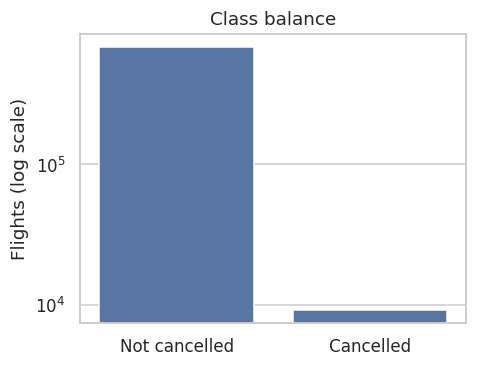

In [53]:
counts = df["Cancelled"].value_counts().sort_index()
rate = df["Cancelled"].mean()
print(counts.rename({0: "Not cancelled", 1: "Cancelled"}))
print(f"\nCancellation rate: {rate:.3%}   |   imbalance ratio: 1 : {(1 - rate) / rate:.0f}")

fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.barplot(x=["Not cancelled", "Cancelled"], y=counts.values, ax=ax)
ax.set_yscale("log"); ax.set_ylabel("Flights (log scale)"); ax.set_title("Class balance")
plt.tight_layout(); plt.show()

### 3.2 Cancellations over time
Daily cancellation rates show whether cancellations are steady or clustered in events. Clusters matter for the split design and for error analysis later: a model trained mostly on calm days will struggle on event days. The shaded and dashed markers show the CrowdStrike outage (19 to 22 July 2024, which falls in the validation period) and the landfalls of Hurricanes Helene and Milton. *Verify these event dates against a cited source before using them in the report.*

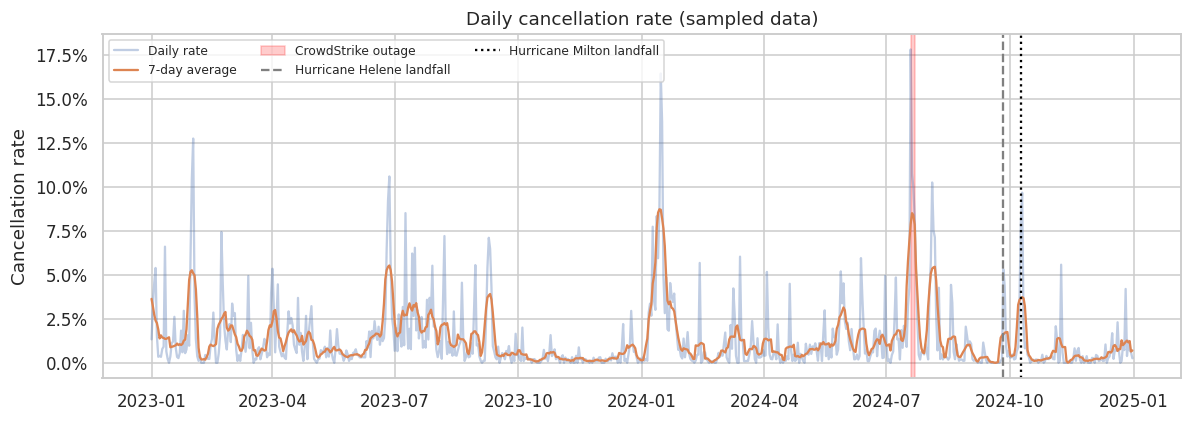

Ten highest-rate days:


,rate,flights,rate_7d
FlightDate,,,
2024-07-19,0.178145,1089,0.078882
2024-01-15,0.164474,912,0.087022
2024-01-16,0.136986,803,0.082072
2023-02-01,0.127485,855,0.050907
2024-07-20,0.107582,976,0.085070
2023-06-27,0.105946,925,0.055329
2023-01-31,0.104839,868,0.052602
2024-08-04,0.102515,1034,0.053543
2024-07-21,0.099718,1063,0.083907


In [54]:
daily = df.groupby("FlightDate")["Cancelled"].agg(rate="mean", flights="size")
daily["rate_7d"] = daily["rate"].rolling(7, center=True, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(daily.index, daily["rate"], alpha=0.35, label="Daily rate")
ax.plot(daily.index, daily["rate_7d"], label="7-day average")
ax.axvspan(pd.Timestamp("2024-07-19"), pd.Timestamp("2024-07-22"), color="red", alpha=0.2, label="CrowdStrike outage")
ax.axvline(pd.Timestamp("2024-09-26"), color="gray", ls="--", label="Hurricane Helene landfall")
ax.axvline(pd.Timestamp("2024-10-09"), color="black", ls=":", label="Hurricane Milton landfall")
ax.set_ylabel("Cancellation rate"); ax.set_title("Daily cancellation rate (sampled data)")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(ncol=3, fontsize=8); plt.tight_layout(); plt.show()

print("Ten highest-rate days:")
daily.sort_values("rate", ascending=False).head(10)

**Interpretation.** *Which days or periods stand out? Do they match known events (winter storms, the outage, hurricanes)? What does that imply for how predictable cancellations are from schedule-time information alone?*

### 3.3 Calendar patterns
Month, day of week and scheduled departure hour are the cheapest schedule-time features. These plots show whether they carry any signal and motivate the cyclical encoding of hour in Part 2.

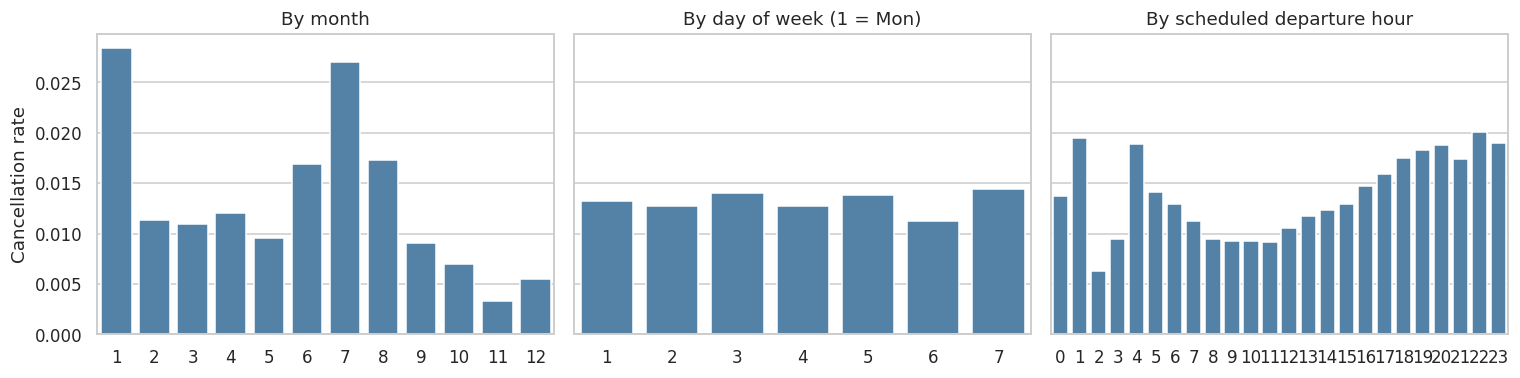

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, (col, title) in zip(axes, [("Month", "By month"), ("DayOfWeek", "By day of week (1 = Mon)"), ("DepHour", "By scheduled departure hour")]):
    r = df.groupby(col)["Cancelled"].mean()
    sns.barplot(x=r.index, y=r.values, ax=ax, color="steelblue")
    ax.set_title(title); ax.set_xlabel(""); 
axes[0].set_ylabel("Cancellation rate")
plt.tight_layout(); plt.show()

### 3.4 Carriers and airports
Rates are noisy for small groups, particularly in a 5% sample, so groups below a minimum flight count are excluded from the airport view. Large differences between carriers or airports justify using them as features, and the spread across airports connects to the equity question in the report (do smaller airports, which resemble many African airports, behave differently?).

Carriers:


,flights,cancelled,rate
Reporting_Airline,,,
WN,142944,1368,0.009570
DL,99497,946,0.009508
AA,95893,1244,0.012973
UA,74040,1158,0.015640
OO,71201,829,0.011643
YX,29885,660,0.022085
NK,26214,479,0.018273
B6,25557,446,0.017451
MQ,25178,327,0.012988


Airports with at least 1,000 sampled departures: 99 (of 354 total)


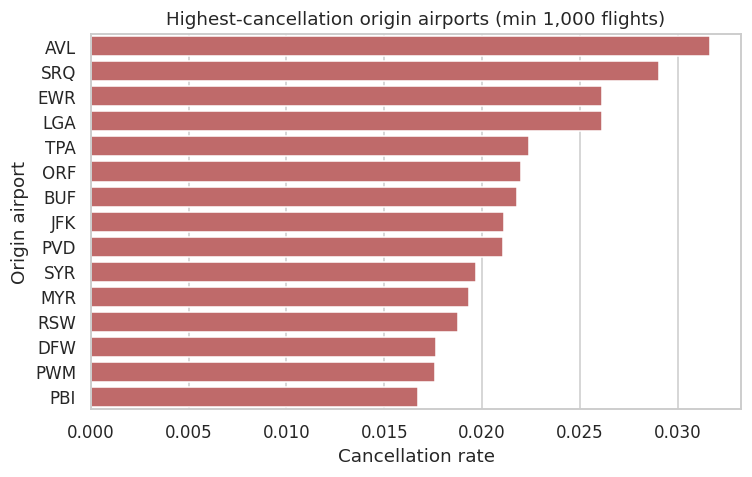

In [56]:
carrier = (df.groupby("Reporting_Airline")["Cancelled"]
             .agg(flights="size", cancelled="sum", rate="mean")
             .sort_values("flights", ascending=False))
print("Carriers:")
display(carrier)

MIN_FLIGHTS = 1000
origin = (df.groupby("Origin")["Cancelled"].agg(flights="size", rate="mean"))
origin = origin[origin["flights"] >= MIN_FLIGHTS]
print(f"Airports with at least {MIN_FLIGHTS:,} sampled departures: {len(origin)} "
      f"(of {df['Origin'].nunique()} total)")

top = origin.sort_values("rate", ascending=False).head(15)
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=top["rate"], y=top.index, ax=ax, color="indianred")
ax.set_xlabel("Cancellation rate"); ax.set_ylabel("Origin airport")
ax.set_title(f"Highest-cancellation origin airports (min {MIN_FLIGHTS:,} flights)")
plt.tight_layout(); plt.show()

**Interpretation.** *Which carriers and airports are over- or under-represented in cancellations? Are the highest-rate airports large hubs or smaller airports? Is the carrier effect plausibly operational (network structure, regional partners) or an artefact of how BTS defines reporting carriers?*

### 3.5 Engineered schedule-time features
The congestion counts and trailing cancellation rates were created in `build_dataset.py`. Binning each into deciles and plotting the cancellation rate per bin is a quick empirical check on whether they carry signal. This is the first piece of evidence for the feature-engineering section of the report; the with/without comparison experiment comes in Part 2.

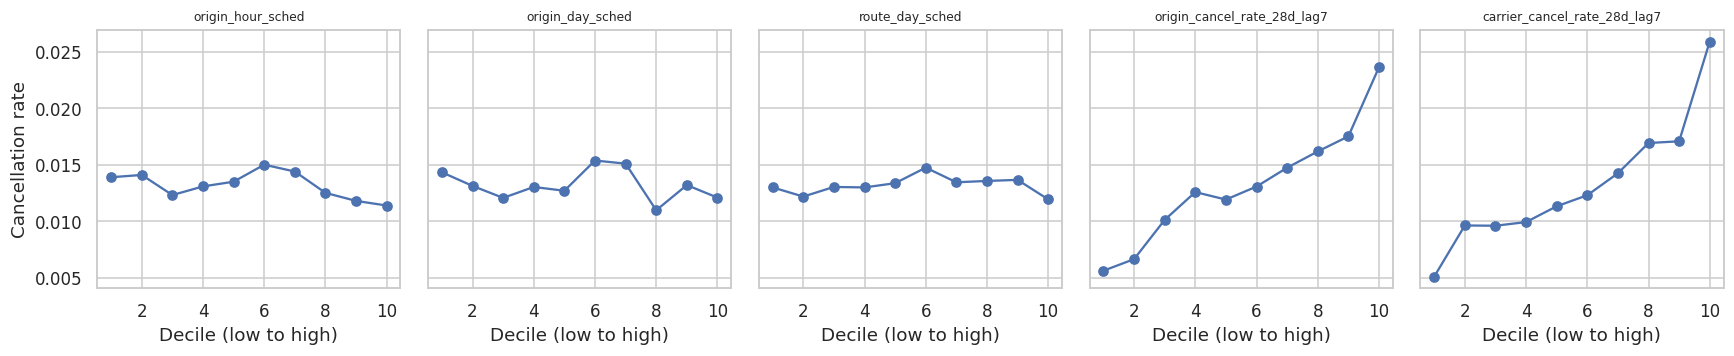

Correlation with target (point-biserial via Pearson):


carrier_cancel_rate_28d_lag7    0.042063
origin_cancel_rate_28d_lag7     0.039985
route_day_sched                -0.000343
CRSElapsedTime                 -0.002342
origin_day_sched               -0.002763
origin_hour_sched              -0.005738
Distance                       -0.006135
Name: Cancelled, dtype: float64

In [57]:
eng_features = ["origin_hour_sched", "origin_day_sched", "route_day_sched",
                "origin_cancel_rate_28d_lag7", "carrier_cancel_rate_28d_lag7"]

fig, axes = plt.subplots(1, len(eng_features), figsize=(16, 3.4), sharey=True)
for ax, feat in zip(axes, eng_features):
    bins = pd.qcut(df[feat], q=10, duplicates="drop")
    r = df.groupby(bins, observed=True)["Cancelled"].mean().reset_index(drop=True)
    ax.plot(range(1, len(r) + 1), r.values, marker="o")
    ax.set_title(feat, fontsize=8); ax.set_xlabel("Decile (low to high)")
axes[0].set_ylabel("Cancellation rate")
plt.tight_layout(); plt.show()

print("Correlation with target (point-biserial via Pearson):")
df[eng_features + ["Distance", "CRSElapsedTime", "Cancelled"]].corr()["Cancelled"].drop("Cancelled").sort_values(ascending=False)

**Interpretation.** *Which features show a clear monotonic relationship with cancellation and which look flat? Weak linear correlation does not rule out a useful non-linear effect, which is one reason tree-based models are compared against logistic regression in Part 2.*

## 4. Leakage audit and temporal split

### 4.1 Leakage audit
Prediction is framed as happening **at schedule publication, days before departure**. Any column recorded during or after the flight would let the model cheat, so the cell below fails loudly if one is present.

In [58]:
FORBIDDEN = {"DepTime", "DepDelay", "ArrTime", "ArrDelay", "TaxiOut", "TaxiIn", "WheelsOff", "WheelsOn",
             "AirTime", "ActualElapsedTime", "CancellationCode", "CarrierDelay", "WeatherDelay",
             "NASDelay", "SecurityDelay", "LateAircraftDelay"}
leaked = FORBIDDEN & set(df.columns)
assert not leaked, f"Leaky columns present: {leaked}"
print("No post-departure columns found. Available columns:")
print(list(df.columns))

No post-departure columns found. Available columns:
['Year', 'Month', 'DayofMonth', 'DayOfWeek', 'FlightDate', 'Reporting_Airline', 'Origin', 'OriginState', 'Dest', 'DestState', 'CRSDepTime', 'CRSArrTime', 'Cancelled', 'CRSElapsedTime', 'Distance', 'DepHour', 'origin_hour_sched', 'origin_day_sched', 'dest_day_sched', 'route_day_sched', 'origin_cancel_rate_28d_lag7', 'carrier_cancel_rate_28d_lag7']


### 4.2 Temporal split
A random split would let the model see flights from the same day or week as the test flights, which overstates performance relative to real use. Instead, the data is split by date: **train** Jan 2023 to Jun 2024, **validation** Jul to Sep 2024, **test** Oct to Dec 2024. Validation and test keep the natural class balance; any resampling is applied to the training set only. The test set is touched once, at the end.

In [59]:
TRAIN_END = pd.Timestamp("2024-06-30")
VAL_START, VAL_END = pd.Timestamp("2024-07-01"), pd.Timestamp("2024-09-30")
TEST_START = pd.Timestamp("2024-10-01")

train = df[df["FlightDate"] <= TRAIN_END].copy()
val = df[(df["FlightDate"] >= VAL_START) & (df["FlightDate"] <= VAL_END)].copy()
test = df[df["FlightDate"] >= TEST_START].copy()

assert len(train) + len(val) + len(test) == len(df)
assert train["FlightDate"].max() < val["FlightDate"].min() <= val["FlightDate"].max() < test["FlightDate"].min()

summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "from": [d["FlightDate"].min().date() for d in (train, val, test)],
    "to": [d["FlightDate"].max().date() for d in (train, val, test)],
    "rows": [len(d) for d in (train, val, test)],
    "cancelled": [int(d["Cancelled"].sum()) for d in (train, val, test)],
    "cancel_rate": [d["Cancelled"].mean() for d in (train, val, test)],
})
summary["share_of_data"] = summary["rows"] / summary["rows"].sum()
summary.style.format({"cancel_rate": "{:.3%}", "share_of_data": "{:.1%}"})

,split,from,to,rows,cancelled,cancel_rate,share_of_data
0,train,2023-01-01,2024-06-30,514176,6833,1.329%,74.0%
1,validation,2024-07-01,2024-09-30,91555,1687,1.843%,13.2%
2,test,2024-10-01,2024-12-31,88917,652,0.733%,12.8%


### 4.3 Event window and unseen categories
The CrowdStrike outage produced an unusual spike inside the validation period. Tuning hyperparameters on a window dominated by a one-off event could mislead model selection, so the validation set is flagged and results are reported with and without those four days. Separately, because the split is temporal, validation or test may contain airports, routes or carriers never seen in training; the encoding strategy in Part 2 must handle that, so the size of the problem is measured here.

In [60]:
CS_START, CS_END = pd.Timestamp("2024-07-19"), pd.Timestamp("2024-07-22")
val["crowdstrike_window"] = val["FlightDate"].between(CS_START, CS_END)
print(f"Validation cancellation rate inside the window:  {val.loc[val.crowdstrike_window, 'Cancelled'].mean():.3%} "
      f"({val.crowdstrike_window.sum():,} flights)")
print(f"Validation cancellation rate outside the window: {val.loc[~val.crowdstrike_window, 'Cancelled'].mean():.3%}")
val_clean = val[~val["crowdstrike_window"]]

print("\nShare of rows with a category unseen in training:")
for col in ["Reporting_Airline", "Origin", "Dest"]:
    seen = set(train[col].unique())
    print(f"  {col:18s} validation: {(~val[col].isin(seen)).mean():.2%}   test: {(~test[col].isin(seen)).mean():.2%}")
train["route"] = train["Origin"] + "-" + train["Dest"]
val["route"] = val["Origin"] + "-" + val["Dest"]
test["route"] = test["Origin"] + "-" + test["Dest"]
seen_routes = set(train["route"].unique())
print(f"  {'route':18s} validation: {(~val['route'].isin(seen_routes)).mean():.2%}   test: {(~test['route'].isin(seen_routes)).mean():.2%}")

Validation cancellation rate inside the window:  11.720% (4,249 flights)
Validation cancellation rate outside the window: 1.362%

Share of rows with a category unseen in training:
  Reporting_Airline  validation: 0.00%   test: 0.00%
  Origin             validation: 0.00%   test: 0.01%
  Dest               validation: 0.00%   test: 0.01%
  route              validation: 0.24%   test: 0.31%


## Part 1 summary
*Write three or four sentences in your own words: the class imbalance, what the time series and calendar plots revealed, which engineered features look informative, and how large the unseen-category problem is. These notes feed directly into the Methodology and Discussion sections of the report.*

Looking at the data the class imbalce is overwhelmingly huge, our target class (cancelled) is like 1-3% of the dataset. I think this will make accuracy meaningless becasue the model will have  98% accuracy without learning anyhting. The real metric will be precision/AUC. The time calendar revelead that there's more cancelation in January and in the summer months (June, July. August) this will be treated as a hypothesis because each month appear only 2 times so if a month have an even in it this could trick the model to think that this month is bad news. For December we don't have december 2022, about the hour of the day it rises linearly from 9PAM to 10PM. And day of the week saturdays are lower while sundays and wednesdays appears higher. The temporal split shows how test have a very small percentage of the target class partly bacause the month that it covers are quiter(prevalance shift), and also the validation set 30% of it is just 4 days of crowdstruke outage which drives uo the numbers.

**Next (Part 2):** preprocessing pipeline, feature engineering experiments (with vs without engineered features), and the traditional ML models with hyperparameter tuning and experiment logging.

In [61]:
win = val[val["crowdstrike_window"]]
win.groupby("Reporting_Airline")["Cancelled"].agg(flights="size", rate="mean").sort_values("rate", ascending=False)

,flights,rate
Reporting_Airline,,
DL,646,0.431889
9E,123,0.341463
UA,433,0.157044
G4,106,0.150943
NK,166,0.132530
OH,141,0.070922
F9,121,0.066116
AA,567,0.061728
YX,172,0.046512


In [62]:
daily_c = df.groupby("FlightDate")["Cancelled"].sum().sort_values(ascending=False)
for k in (10, 20, 50):
    print(f"Top {k} days ({k/len(daily_c):.1%} of days): {daily_c.head(k).sum()/daily_c.sum():.1%} of all cancellations")


Top 10 days (1.4% of days): 12.9% of all cancellations
Top 20 days (2.7% of days): 21.3% of all cancellations
Top 50 days (6.8% of days): 38.9% of all cancellations


# Part 2: Preprocessing, feature engineering and traditional ML
**How to use this notebook.** Paste these cells *below* Part 1 in the same Kaggle notebook (the repository should hold one notebook). Part 2 reuses `train`, `val`, `test` and the CrowdStrike flag from Part 1, and the next cell rebuilds them automatically if you run Part 2 on its own.

**Protocol (fixed for every experiment, so rows in the results table are comparable):**
- Fit on the **training period** (Jan 2023 to Jun 2024). Hyperparameter search uses **time-aware cross-validation inside training** only.
- Compare models on **`val_clean`** (validation without the four CrowdStrike days). The full validation set is reported alongside.
- Primary metric: **PR-AUC** (average precision), also reported as **lift** over the base rate (PR-AUC divided by prevalence). Secondary: ROC-AUC, and precision and recall when the riskiest 2% of flights are flagged.
- The **test set is not touched** in this notebook. It is used once, in Part 3, for the final ML vs DL comparison.

## 1. Setup and configuration
`TargetEncoder` needs scikit-learn 1.3 or newer. The configuration values at the end of the cell control the compute budget, so they can be lowered for a quick dry run and raised for the final run.

In [63]:
import os, json, time, glob, shutil, warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy.stats import loguniform
from pandas.tseries.holiday import USFederalHolidayCalendar
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             roc_curve, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
print("scikit-learn", sklearn.__version__)

SEED = globals().get("SEED", 42)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

# ---- compute budget / configuration ----
OUT_DIR = os.environ.get("OUT_DIR", "/kaggle/working")
SEARCH_ITER = int(os.environ.get("SEARCH_ITER", 12))   # random-search candidates for HGB
RF_TREES = int(os.environ.get("RF_TREES", 200))
SVM_ROWS = int(os.environ.get("SVM_ROWS", 200_000))    # training rows used for the linear SVM
ALERT_FRAC = 0.02                                       # "flag the riskiest 2% of flights"
USE_WANDB = True                                        # offline mode; falls back silently if unavailable
os.makedirs(OUT_DIR, exist_ok=True)

scikit-learn 1.6.1


### 1.1 Data (only runs if Part 1 variables are missing)
When Part 2 sits below Part 1, `train` already exists and this cell does nothing. Otherwise it repeats the loading and the temporal split from Part 1 exactly. In both cases `val_clean` is rebuilt from `val` here, because in Part 1 it was created before the `route` column was added.

In [64]:
if "train" not in globals():
    DATA_ROOT = os.environ.get("DATA_ROOT", "/kaggle/input")
    files = [p for p in glob.glob(f"{DATA_ROOT}/**/*", recursive=True)
             if os.path.basename(p).startswith("bts_flights") and p.endswith((".csv", ".csv.gz"))]
    assert len(files) == 1, f"Expected exactly one data file, found: {files}"
    df = pd.read_csv(files[0], parse_dates=["FlightDate"])
    train = df[df["FlightDate"] <= "2024-06-30"].copy()
    val = df[(df["FlightDate"] >= "2024-07-01") & (df["FlightDate"] <= "2024-09-30")].copy()
    test = df[df["FlightDate"] >= "2024-10-01"].copy()

val = val.copy()
val["crowdstrike_window"] = val["FlightDate"].between(pd.Timestamp("2024-07-19"), pd.Timestamp("2024-07-22"))
mask_clean = ~val["crowdstrike_window"].values
print(f"train {len(train):,} | validation {len(val):,} (clean: {mask_clean.sum():,}) | test {len(test):,} (not used here)")

train 514,176 | validation 91,555 (clean: 87,306) | test 88,917 (not used here)


## 2. Feature engineering and the modelling matrix
Every transformation below is **stateless** (it depends only on the row itself), so applying it to train, validation and test cannot leak information. Transformations that learn from data (imputation, scaling, encoding) live inside the scikit-learn pipeline and are fitted on training data only.

| Feature group | What and why |
|---|---|
| Cyclical time | Scheduled departure and arrival time as sine and cosine of the time of day, so 23:50 and 00:10 are close. |
| Holiday window | 1 if the date is within one day of a US federal holiday (demand and staffing pressure). |
| Congestion (log) | Scheduled departures from the origin that hour and day, arrivals at the destination, flights on the route that day. Log-transformed because counts are right-skewed. |
| Trailing cancellation rates | 28-day rate for the origin and for the carrier, lagged 7 days (built in `build_dataset.py`). |
| Month (seasonality) | Sine and cosine of month, kept **out of the main feature set** and tested as a separate experiment, since each month appears only twice. |
| Identity | Carrier and day of week are one-hot encoded. Origin, destination and route have too many levels for one-hot, so they are **target-encoded** (smoothed cancellation rate, fitted out-of-fold inside the pipeline; unseen routes fall back to the overall rate). |

In [65]:
HOLIDAYS = USFederalHolidayCalendar().holidays(start="2022-12-01", end="2025-01-31")
HOLIDAY_WINDOW = {h + pd.Timedelta(days=k) for h in HOLIDAYS for k in (-1, 0, 1)}

def add_features(d):
    # stateless feature construction: safe to apply identically to every split
    out = pd.DataFrame(index=d.index)
    dep_t = (d["CRSDepTime"] // 100) % 24 + (d["CRSDepTime"] % 100) / 60
    arr_t = (d["CRSArrTime"] // 100) % 24 + (d["CRSArrTime"] % 100) / 60
    for name, t in (("dep", dep_t), ("arr", arr_t)):
        out[f"{name}_hour_sin"] = np.sin(2 * np.pi * t / 24)
        out[f"{name}_hour_cos"] = np.cos(2 * np.pi * t / 24)
    out["month_sin"] = np.sin(2 * np.pi * d["Month"] / 12)
    out["month_cos"] = np.cos(2 * np.pi * d["Month"] / 12)
    out["CRSElapsedTime"] = d["CRSElapsedTime"]
    out["Distance"] = d["Distance"]
    out["is_holiday_window"] = d["FlightDate"].isin(HOLIDAY_WINDOW).astype(int)
    for c in ["origin_hour_sched", "origin_day_sched", "dest_day_sched", "route_day_sched"]:
        out[c + "_log"] = np.log1p(d[c])
    out["origin_cancel_rate_28d_lag7"] = d["origin_cancel_rate_28d_lag7"]
    out["carrier_cancel_rate_28d_lag7"] = d["carrier_cancel_rate_28d_lag7"]
    out["DayOfWeek"] = d["DayOfWeek"]
    out["Reporting_Airline"] = d["Reporting_Airline"]
    out["Origin"], out["Dest"] = d["Origin"], d["Dest"]
    out["route"] = d["Origin"] + "-" + d["Dest"]
    return out

X_train, y_train = add_features(train), train["Cancelled"].to_numpy()
X_val, y_val = add_features(val), val["Cancelled"].to_numpy()

BASE_NUM = ["CRSElapsedTime", "Distance", "dep_hour_sin", "dep_hour_cos",
            "arr_hour_sin", "arr_hour_cos", "is_holiday_window"]
ENG_NUM = ["origin_hour_sched_log", "origin_day_sched_log", "dest_day_sched_log", "route_day_sched_log",
           "origin_cancel_rate_28d_lag7", "carrier_cancel_rate_28d_lag7"]
CATS = dict(ohe=["Reporting_Airline", "DayOfWeek"], te=["Origin", "Dest", "route"])
FEATURE_SETS = {
    "trailing_only": dict(num=["origin_cancel_rate_28d_lag7", "carrier_cancel_rate_28d_lag7"], ohe=[], te=[]),
    "base": dict(num=BASE_NUM, **CATS),
    "engineered": dict(num=BASE_NUM + ENG_NUM, **CATS),
    "engineered+month": dict(num=BASE_NUM + ENG_NUM + ["month_sin", "month_cos"], **CATS),
}
print({k: len(v["num"]) + len(v["ohe"]) + len(v["te"]) for k, v in FEATURE_SETS.items()}, "raw input columns per feature set")
print(f"Prevalence  train: {y_train.mean():.3%} | val_clean: {y_val[mask_clean].mean():.3%} | val (full): {y_val.mean():.3%}")

{'trailing_only': 2, 'base': 12, 'engineered': 18, 'engineered+month': 20} raw input columns per feature set
Prevalence  train: 1.329% | val_clean: 1.362% | val (full): 1.843%


## 3. Evaluation, logging and pipeline helpers
**Metrics.** Besides PR-AUC and ROC-AUC, the table reports precision and recall when the **riskiest 2% of flights are flagged**. This "alert budget" view does not need a probability threshold, so it works for every model (including the SVM) and is more stable than a fixed threshold when the prevalence shifts between periods.

**Logging.** Every run is stored in `experiments.csv` and, if Weights & Biases is installed, in an offline W&B run, so each row of the report's experiment table can be traced to a logged run.

**Pipelines.** One builder creates the preprocessing (impute, optionally scale, one-hot, target-encode) for every model, so the only thing that changes between experiments is what the experiment is about.

In [66]:
RESULTS, MODELS, SCORES, OBSERVATIONS = {}, {}, {}, {}
_wandb_warned = False

def top_k_metrics(y, s, k=ALERT_FRAC):
    rng = np.random.default_rng(SEED)
    order = np.argsort(-(s + rng.normal(0, 1e-12, len(s))))   # tiny jitter breaks ties
    n_alert = max(1, int(round(k * len(y))))
    tp = y[order[:n_alert]].sum()
    return tp / n_alert, tp / max(1, y.sum())

def score_block(y, s):
    ap = average_precision_score(y, s)
    p, r = top_k_metrics(y, s)
    return dict(ap=ap, lift=ap / y.mean(), auc=roc_auc_score(y, s), prec_top=p, rec_top=r)

def predict_scores(pipe, X):
    if hasattr(pipe, "predict_proba"):
        return pipe.predict_proba(X)[:, 1]
    return pipe.decision_function(X)

def log_wandb(row):
    global _wandb_warned
    if not USE_WANDB:
        return
    try:
        import wandb
        os.environ["WANDB_MODE"] = "offline"
        os.environ["WANDB_SILENT"] = "true"
        run = wandb.init(project="flight-cancellation", name=row["id"], config=row, dir=OUT_DIR, reinit=True)
        run.log({k: v for k, v in row.items() if isinstance(v, (int, float)) and v == v})
        run.finish()
    except Exception as e:
        if not _wandb_warned:
            print(f"(W&B offline logging unavailable: {type(e).__name__}; using experiments.csv only)")
            _wandb_warned = True

def build_pipeline(model, fset, scale):
    spec = FEATURE_SETS[fset]
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    parts = [("num", Pipeline(num_steps), spec["num"])]
    if spec["ohe"]:
        parts.append(("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), spec["ohe"]))
    if spec["te"]:
        parts.append(("te", TargetEncoder(target_type="binary", smooth="auto", cv=5, shuffle=True,
                                          random_state=SEED), spec["te"]))
    prep = ColumnTransformer(parts, remainder="drop", sparse_threshold=0)
    return Pipeline([("prep", prep), ("model", model)])

def run_experiment(exp_id, model_name, pipe, fset, imbalance="none", params="", train_idx=None,
                   prefit=False, fit_seconds=None, cv=None):
    if prefit:
        n_train = len(X_train)
    else:
        idx = np.arange(len(X_train)) if train_idx is None else train_idx
        t0 = time.time()
        pipe.fit(X_train.iloc[idx], y_train[idx])
        fit_seconds, n_train = time.time() - t0, len(idx)
    s = predict_scores(pipe, X_val)
    vc, vf = score_block(y_val[mask_clean], s[mask_clean]), score_block(y_val, s)
    row = dict(id=exp_id, model=model_name, features=fset, imbalance=imbalance, hyperparameters=str(params),
               n_train=n_train, cv_ap=cv[0] if cv else np.nan, cv_ap_std=cv[1] if cv else np.nan,
               vc_ap=vc["ap"], vc_lift=vc["lift"], vc_auc=vc["auc"], vc_prec_top2=vc["prec_top"],
               vc_rec_top2=vc["rec_top"], vf_ap=vf["ap"], fit_s=fit_seconds)
    RESULTS[exp_id], MODELS[exp_id], SCORES[exp_id] = row, pipe, s
    pd.DataFrame(RESULTS.values()).to_csv(os.path.join(OUT_DIR, "experiments.csv"), index=False)
    log_wandb(row)
    print(f"{exp_id} {model_name:<22s} [{fset}] val_clean PR-AUC {vc['ap']:.4f} (lift {vc['lift']:.1f}x) "
          f"| ROC-AUC {vc['auc']:.3f} | top-2% precision {vc['prec_top']:.3f}, recall {vc['rec_top']:.3f} "
          f"| fit {fit_seconds:.0f}s")
    return pipe

def results_table():
    t = pd.DataFrame(RESULTS.values())
    t["observation"] = t["id"].map(OBSERVATIONS).fillna("(write why the result changed)")
    return t.sort_values("id").reset_index(drop=True)

## 4. Time-aware cross-validation
Random K-fold would mix future and past flights, so the model would be scored on days surrounded by training days. Instead the search uses **expanding windows**: each fold trains on everything up to a cut-off and validates on the following quarter. Folds are defined by date, not by row position.

In [67]:
FOLD_SPEC = [("2023-09-30", "2023-10-01", "2023-12-31"),
             ("2023-12-31", "2024-01-01", "2024-03-31"),
             ("2024-03-31", "2024-04-01", "2024-06-30")]
dates = train["FlightDate"].to_numpy()
CV_FOLDS = []
for tr_end, te_start, te_end in FOLD_SPEC:
    tr = np.where(dates <= np.datetime64(tr_end))[0]
    te = np.where((dates >= np.datetime64(te_start)) & (dates <= np.datetime64(te_end)))[0]
    CV_FOLDS.append((tr, te))
    print(f"train up to {tr_end}: {len(tr):>7,} rows | validate {te_start} to {te_end}: {len(te):>6,} rows, "
          f"cancel rate {y_train[te].mean():.3%}")

train up to 2023-09-30: 255,036 rows | validate 2023-10-01 to 2023-12-31: 86,532 rows, cancel rate 0.321%
train up to 2023-12-31: 341,568 rows | validate 2024-01-01 to 2024-03-31: 82,729 rows, cancel rate 1.745%
train up to 2024-03-31: 424,297 rows | validate 2024-04-01 to 2024-06-30: 89,879 rows, cancel rate 1.130%


**Interpretation.** *The fold cancellation rates differ (the January to March fold contains winter storms). What does that mean for comparing CV scores across folds, and why is PR-AUC averaged per fold rather than pooled?*

## 5. Baselines
Every later result must beat these. **E00** predicts the training prevalence for every flight, so its PR-AUC equals the validation prevalence (lift 1.0) and shows what "no skill" scores. **E01** is a logistic regression using only the two trailing cancellation rates, the simplest "recent history" predictor, and sets the bar the full feature set has to clear.

In [68]:
run_experiment("E00", "Dummy (prior)",
               build_pipeline(DummyClassifier(strategy="prior"), "trailing_only", scale=False),
               "trailing_only", params="strategy=prior")
run_experiment("E01", "Logistic regression",
               build_pipeline(LogisticRegression(max_iter=1000, random_state=SEED), "trailing_only", scale=True),
               "trailing_only", params="C=1.0")

E00 Dummy (prior)          [trailing_only] val_clean PR-AUC 0.0136 (lift 1.0x) | ROC-AUC 0.500 | top-2% precision 0.015, recall 0.022 | fit 0s
E01 Logistic regression    [trailing_only] val_clean PR-AUC 0.0213 (lift 1.6x) | ROC-AUC 0.636 | top-2% precision 0.028, recall 0.041 | fit 1s


Pipeline(steps=[('prep',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['origin_cancel_rate_28d_lag7',
                                                   'carrier_cancel_rate_28d_lag7'])])),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])

## 6. Logistic regression: the feature-engineering ablation
**E02** uses calendar, schedule and identity features only. **E03** adds the engineered congestion and trailing-rate features, so E02 vs E03 isolates what feature engineering contributes. **E04** repeats E03 with balanced class weights, which up-weights cancellations in the loss to counter the 1:70 imbalance.

In [69]:
LR = lambda **kw: LogisticRegression(max_iter=1000, random_state=SEED, **kw)
run_experiment("E02", "Logistic regression", build_pipeline(LR(), "base", True), "base", params="C=1.0")
run_experiment("E03", "Logistic regression", build_pipeline(LR(), "engineered", True), "engineered", params="C=1.0")
run_experiment("E04", "Logistic regression", build_pipeline(LR(class_weight="balanced"), "engineered", True),
               "engineered", imbalance="class_weight=balanced", params="C=1.0")

E02 Logistic regression    [base] val_clean PR-AUC 0.0308 (lift 2.3x) | ROC-AUC 0.660 | top-2% precision 0.057, recall 0.083 | fit 3s
E03 Logistic regression    [engineered] val_clean PR-AUC 0.0324 (lift 2.4x) | ROC-AUC 0.682 | top-2% precision 0.065, recall 0.096 | fit 5s
E04 Logistic regression    [engineered] val_clean PR-AUC 0.0302 (lift 2.2x) | ROC-AUC 0.672 | top-2% precision 0.052, recall 0.077 | fit 30s


Pipeline(steps=[('prep',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['CRSElapsedTime', 'Distance',
                                                   'dep_hour_sin',
                                                   'dep_hour_cos',
                                                   'arr_hour_sin',
                                                   'arr_hour_cos',
                                                   'is_holiday_window',
                                                   'origin_hour_sched_log',
                                                   'origin_day_sched_log',
                                                   'dest_day_sched_log',
                                                   'r...y_sched_log',
                                                   'origin_cancel_rate_28d_lag7',
                                                   'carrier_cancel_rate_28d_lag7']),
                                                 ('ohe',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Reporting_Airline',
                                                   'DayOfWeek']),
                                                 ('te',
                                                  TargetEncoder(random_state=42,
                                                                target_type='binary'),
                                                  ['Origin', 'Dest',
                                                   'route'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

## 7. Tree ensembles
Tree models capture non-linear effects and interactions (for example, congestion mattering only at certain airports), which a linear model cannot. **E05** and **E06** repeat the base vs engineered comparison with histogram gradient boosting (HGB), which is fast on hundreds of thousands of rows and is deliberately regularised (small learning rate, large leaves, early stopping). **E07** adds month seasonality to test the hypothesis from Part 1 that month effects are driven by a few events and do not generalise. **E08** is a random forest, a bagging-based alternative with different bias and variance behaviour.

In [70]:
HGB_DEFAULT = dict(learning_rate=0.08, max_iter=300, max_leaf_nodes=31, min_samples_leaf=200,
                   early_stopping=True, n_iter_no_change=20, validation_fraction=0.1, random_state=SEED)
hgb = lambda **kw: HistGradientBoostingClassifier(**{**HGB_DEFAULT, **kw})

run_experiment("E05", "HistGradientBoosting", build_pipeline(hgb(), "base", False), "base", params=HGB_DEFAULT)
run_experiment("E06", "HistGradientBoosting", build_pipeline(hgb(), "engineered", False), "engineered", params=HGB_DEFAULT)
run_experiment("E07", "HistGradientBoosting", build_pipeline(hgb(), "engineered+month", False),
               "engineered+month", params=HGB_DEFAULT)

RF_PARAMS = dict(n_estimators=RF_TREES, min_samples_leaf=50, max_features="sqrt", max_samples=0.5)
run_experiment("E08", "Random forest",
               build_pipeline(RandomForestClassifier(**RF_PARAMS, n_jobs=-1, random_state=SEED), "engineered", False),
               "engineered", params=RF_PARAMS)

E05 HistGradientBoosting   [base] val_clean PR-AUC 0.0297 (lift 2.2x) | ROC-AUC 0.644 | top-2% precision 0.056, recall 0.082 | fit 9s
E06 HistGradientBoosting   [engineered] val_clean PR-AUC 0.0315 (lift 2.3x) | ROC-AUC 0.651 | top-2% precision 0.069, recall 0.102 | fit 21s
E07 HistGradientBoosting   [engineered+month] val_clean PR-AUC 0.0312 (lift 2.3x) | ROC-AUC 0.671 | top-2% precision 0.052, recall 0.077 | fit 28s
E08 Random forest          [engineered] val_clean PR-AUC 0.0326 (lift 2.4x) | ROC-AUC 0.655 | top-2% precision 0.070, recall 0.103 | fit 93s


Pipeline(steps=[('prep',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['CRSElapsedTime', 'Distance',
                                                   'dep_hour_sin',
                                                   'dep_hour_cos',
                                                   'arr_hour_sin',
                                                   'arr_hour_cos',
                                                   'is_holiday_window',
                                                   'origin_hour_sched_log',
                                                   'origin_day_sched_log',
                                                   'dest_day_sched_log',
                                                   'route_day_sched_log',
                                                   'origin...ate_28d_lag7',
                                                   'carrier_cancel_rate_28d_lag7']),
                                                 ('ohe',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Reporting_Airline',
                                                   'DayOfWeek']),
                                                 ('te',
                                                  TargetEncoder(random_state=42,
                                                                target_type='binary'),
                                                  ['Origin', 'Dest',
                                                   'route'])])),
                ('model',
                 RandomForestClassifier(max_samples=0.5, min_samples_leaf=50,
                                        n_estimators=200, n_jobs=-1,
                                        random_state=42))])

## 8. Linear SVM
A kernel (RBF) SVM scales roughly quadratically with the number of rows and is impractical at 500,000 samples, so a **linear SVM on a random subsample** of the training data is used. This is a deliberate accuracy-versus-compute trade-off to discuss in the report. The SVM outputs a decision score instead of a probability, which is enough for PR-AUC, ROC-AUC and the alert-budget metrics.

In [71]:
rng = np.random.default_rng(SEED)
svm_idx = np.sort(rng.choice(len(X_train), size=min(SVM_ROWS, len(X_train)), replace=False))
SVM_PARAMS = dict(C=0.1, class_weight="balanced", dual=False, max_iter=2000)
run_experiment("E09", "Linear SVM",
               build_pipeline(LinearSVC(**SVM_PARAMS, random_state=SEED), "engineered", True),
               "engineered", imbalance="class_weight=balanced", params=SVM_PARAMS, train_idx=svm_idx)

E09 Linear SVM             [engineered] val_clean PR-AUC 0.0294 (lift 2.2x) | ROC-AUC 0.671 | top-2% precision 0.051, recall 0.075 | fit 7s


Pipeline(steps=[('prep',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['CRSElapsedTime', 'Distance',
                                                   'dep_hour_sin',
                                                   'dep_hour_cos',
                                                   'arr_hour_sin',
                                                   'arr_hour_cos',
                                                   'is_holiday_window',
                                                   'origin_hour_sched_log',
                                                   'origin_day_sched_log',
                                                   'dest_day_sched_log',
                                                   'r...log',
                                                   'origin_cancel_rate_28d_lag7',
                                                   'carrier_cancel_rate_28d_lag7']),
                                                 ('ohe',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Reporting_Airline',
                                                   'DayOfWeek']),
                                                 ('te',
                                                  TargetEncoder(random_state=42,
                                                                target_type='binary'),
                                                  ['Origin', 'Dest',
                                                   'route'])])),
                ('model',
                 LinearSVC(C=0.1, class_weight='balanced', dual=False,
                           max_iter=2000, random_state=42))])

## 9. Hyperparameter tuning (HGB)
HGB with engineered features is tuned by **randomized search with the time-aware folds** from section 4, scored by PR-AUC. The search covers the learning rate, tree size, leaf size and L2 regularisation, which together control model capacity (bias versus variance). Random search covers more of the space than a grid for the same budget. Early stopping chooses the number of boosting rounds.

In [72]:
HGB_FIXED = dict(max_iter=500, early_stopping=True, n_iter_no_change=20, validation_fraction=0.1, random_state=SEED)
search = RandomizedSearchCV(
    build_pipeline(HistGradientBoostingClassifier(**HGB_FIXED), "engineered", False),
    param_distributions={"model__learning_rate": loguniform(0.02, 0.2),
                         "model__max_leaf_nodes": [15, 31, 63, 127],
                         "model__min_samples_leaf": [50, 100, 300, 1000],
                         "model__l2_regularization": loguniform(1e-3, 10)},
    n_iter=SEARCH_ITER, scoring="average_precision", cv=CV_FOLDS, random_state=SEED,
    n_jobs=1, refit=True, verbose=1)
t0 = time.time()
search.fit(X_train, y_train)
search_seconds = time.time() - t0

cvr = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
cols = ["rank_test_score", "mean_test_score", "std_test_score", "param_model__learning_rate",
        "param_model__max_leaf_nodes", "param_model__min_samples_leaf", "param_model__l2_regularization"]
display(cvr[cols].head(8).round(4))
best_params = {k.replace("model__", ""): (round(float(v), 5) if isinstance(v, (float, np.floating)) else int(v))
               for k, v in search.best_params_.items()}
b = search.best_index_
run_experiment("E10", "HGB (tuned)", search.best_estimator_, "engineered", params=best_params, prefit=True,
               fit_seconds=search_seconds, cv=(search.cv_results_["mean_test_score"][b], search.cv_results_["std_test_score"][b]))

Fitting 3 folds for each of 12 candidates, totalling 36 fits


,rank_test_score,mean_test_score,std_test_score,param_model__learning_rate,param_model__max_leaf_nodes,param_model__min_samples_leaf,param_model__l2_regularization
3,1,0.0145,0.0069,0.0210,31,1000,0.6797
1,2,0.0143,0.0069,0.0286,63,300,0.2481
5,3,0.0143,0.0072,0.0403,31,50,0.0054
10,4,0.0142,0.0068,0.0296,63,100,0.2693
7,5,0.0141,0.0067,0.0392,127,300,0.0036
6,6,0.0141,0.0067,0.0391,63,300,0.0534
2,7,0.0140,0.0066,0.1470,127,1000,0.0017
4,8,0.0139,0.0065,0.0326,127,1000,2.1368


E10 HGB (tuned)            [engineered] val_clean PR-AUC 0.0346 (lift 2.5x) | ROC-AUC 0.656 | top-2% precision 0.073, recall 0.108 | fit 1024s


Pipeline(steps=[('prep',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['CRSElapsedTime', 'Distance',
                                                   'dep_hour_sin',
                                                   'dep_hour_cos',
                                                   'arr_hour_sin',
                                                   'arr_hour_cos',
                                                   'is_holiday_window',
                                                   'origin_hour_sched_log',
                                                   'origin_day_sched_log',
                                                   'dest_day_sched_log',
                                                   'route_day_sched_log',
                                                   'origin...
                                                  ['Reporting_Airline',
                                                   'DayOfWeek']),
                                                 ('te',
                                                  TargetEncoder(random_state=42,
                                                                target_type='binary'),
                                                  ['Origin', 'Dest',
                                                   'route'])])),
                ('model',
                 HistGradientBoostingClassifier(early_stopping=True,
                                                l2_regularization=np.float64(0.679657809075816),
                                                learning_rate=np.float64(0.02097077545038924),
                                                max_iter=500,
                                                min_samples_leaf=1000,
                                                n_iter_no_change=20,
                                                random_state=42))])

**Interpretation.** *Which hyperparameters moved the CV score most? Is the best configuration at the edge of a searched range (a sign the range should be widened)? Does the tuned model beat the default (E06) on validation as well as in CV, and what does a gap between the two say about overfitting to the folds?*

## 10. Handling class imbalance
Using the tuned HGB configuration, two standard remedies are compared against doing nothing (E10):
- **E11, class weights:** each cancellation counts about 70 times as much in the loss. The ranking (and therefore PR-AUC) can change, and predicted probabilities are no longer calibrated.
- **E12, random undersampling:** keep every cancellation and a random 10 negatives per positive in the **training set only**. Validation and test keep the natural balance. This trains faster but discards most of the data.

In [73]:
tuned = search.best_estimator_
run_experiment("E11", "HGB (tuned)", clone(tuned).set_params(model__class_weight="balanced"), "engineered",
               imbalance="class_weight=balanced", params=best_params)

def undersample_idx(y, ratio=10, seed=SEED):
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    keep = rng.choice(neg, size=min(len(neg), ratio * len(pos)), replace=False)
    return np.sort(np.concatenate([pos, keep]))

us_idx = undersample_idx(y_train)
run_experiment("E12", "HGB (tuned)", clone(tuned), "engineered", imbalance="undersample 1:10 (train only)",
               params=best_params, train_idx=us_idx)

E11 HGB (tuned)            [engineered] val_clean PR-AUC 0.0352 (lift 2.6x) | ROC-AUC 0.663 | top-2% precision 0.072, recall 0.106 | fit 49s
E12 HGB (tuned)            [engineered] val_clean PR-AUC 0.0317 (lift 2.3x) | ROC-AUC 0.647 | top-2% precision 0.066, recall 0.098 | fit 10s


Pipeline(steps=[('prep',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['CRSElapsedTime', 'Distance',
                                                   'dep_hour_sin',
                                                   'dep_hour_cos',
                                                   'arr_hour_sin',
                                                   'arr_hour_cos',
                                                   'is_holiday_window',
                                                   'origin_hour_sched_log',
                                                   'origin_day_sched_log',
                                                   'dest_day_sched_log',
                                                   'route_day_sched_log',
                                                   'origin...
                                                  ['Reporting_Airline',
                                                   'DayOfWeek']),
                                                 ('te',
                                                  TargetEncoder(random_state=42,
                                                                target_type='binary'),
                                                  ['Origin', 'Dest',
                                                   'route'])])),
                ('model',
                 HistGradientBoostingClassifier(early_stopping=True,
                                                l2_regularization=np.float64(0.679657809075816),
                                                learning_rate=np.float64(0.02097077545038924),
                                                max_iter=500,
                                                min_samples_leaf=1000,
                                                n_iter_no_change=20,
                                                random_state=42))])

## 11. Experiment table
Every row is backed by `experiments.csv` (and an offline W&B run). Metrics are on the **clean validation set** unless the column starts with `vf_` (full validation). Training data is the Jan 2023 to Jun 2024 period, except where `n_train` shows a subsample.

The last column is yours: after looking at the table, write **why** each result changed relative to the previous related run (for example, E02 to E03 isolates feature engineering; E10 to E11 and E12 isolates imbalance handling). Fill in `OBSERVATIONS` below and re-run the cell. This column is the part of the table that earns the most credit.

In [74]:
OBSERVATIONS["E00"] = "No-skill reference: PR-AUC equals the validation prevalence."
# OBSERVATIONS["E03"] = "..."   <- write your own explanation for each experiment
# OBSERVATIONS["E06"] = "..."

table = results_table()
fmt = {"cv_ap": "{:.4f}", "cv_ap_std": "{:.4f}", "vc_ap": "{:.4f}", "vc_lift": "{:.1f}", "vc_auc": "{:.3f}",
       "vc_prec_top2": "{:.3f}", "vc_rec_top2": "{:.3f}", "vf_ap": "{:.4f}", "fit_s": "{:.0f}"}
table.drop(columns=["hyperparameters"]).style.format(fmt, na_rep="-")

,id,model,features,imbalance,n_train,cv_ap,cv_ap_std,vc_ap,vc_lift,vc_auc,vc_prec_top2,vc_rec_top2,vf_ap,fit_s,observation
0,E00,Dummy (prior),trailing_only,none,514176,-,-,0.0136,1.0,0.500,0.015,0.022,0.0184,0,No-skill reference: PR-AUC equals the validation prevalence.
1,E01,Logistic regression,trailing_only,none,514176,-,-,0.0213,1.6,0.636,0.028,0.041,0.0226,1,(write why the result changed)
2,E02,Logistic regression,base,none,514176,-,-,0.0308,2.3,0.660,0.057,0.083,0.0318,3,(write why the result changed)
3,E03,Logistic regression,engineered,none,514176,-,-,0.0324,2.4,0.682,0.065,0.096,0.0321,5,(write why the result changed)
4,E04,Logistic regression,engineered,class_weight=balanced,514176,-,-,0.0302,2.2,0.672,0.052,0.077,0.0300,30,(write why the result changed)
5,E05,HistGradientBoosting,base,none,514176,-,-,0.0297,2.2,0.644,0.056,0.082,0.0308,9,(write why the result changed)
6,E06,HistGradientBoosting,engineered,none,514176,-,-,0.0315,2.3,0.651,0.069,0.102,0.0307,21,(write why the result changed)
7,E07,HistGradientBoosting,engineered+month,none,514176,-,-,0.0312,2.3,0.671,0.052,0.077,0.0344,28,(write why the result changed)
8,E08,Random forest,engineered,none,514176,-,-,0.0326,2.4,0.655,0.070,0.103,0.0319,93,(write why the result changed)
9,E09,Linear SVM,engineered,class_weight=balanced,200000,-,-,0.0294,2.2,0.671,0.051,0.075,0.0290,7,(write why the result changed)


**Interpretation.** *Rank the models by clean-validation PR-AUC and lift. Did engineered features help linear and tree models equally? Did the month features (E07) help, hurt or do nothing, and why? Did class weighting or undersampling improve PR-AUC, or only change precision and recall at a given threshold?*

## 12. Best traditional model and diagnostics
The best non-baseline model by clean-validation PR-AUC is saved as `best_ml_model.joblib`. The saved object is the whole pipeline (preprocessing plus model), so it can score raw rows directly.

In [75]:
candidates = [k for k in RESULTS if k not in ("E00", "E01")]
best_id = max(candidates, key=lambda k: RESULTS[k]["vc_ap"])
best_pipe, best_fset = MODELS[best_id], RESULTS[best_id]["features"]
print(f"Best traditional model: {best_id} ({RESULTS[best_id]['model']}, features={best_fset}), "
      f"clean-val PR-AUC {RESULTS[best_id]['vc_ap']:.4f}, lift {RESULTS[best_id]['vc_lift']:.1f}x")
joblib.dump(best_pipe, os.path.join(OUT_DIR, "best_ml_model.joblib"))

# how does the best model do on the full validation set and inside the outage window?
s = SCORES[best_id]
w = ~mask_clean
rows = {"val_clean": score_block(y_val[mask_clean], s[mask_clean]),
        "val (full)": score_block(y_val, s),
        "outage window only": score_block(y_val[w], s[w])}
pd.DataFrame(rows).T.rename(columns={"ap": "PR-AUC", "lift": "lift", "auc": "ROC-AUC",
                                     "prec_top": "precision@top2%", "rec_top": "recall@top2%"}).round(3)

Best traditional model: E11 (HGB (tuned), features=engineered), clean-val PR-AUC 0.0352, lift 2.6x


,PR-AUC,lift,ROC-AUC,precision@top2%,recall@top2%
val_clean,0.035,2.582,0.663,0.072,0.106
val (full),0.034,1.823,0.571,0.074,0.080
outage window only,0.104,0.890,0.354,0.165,0.028


### 12.1 Precision-recall and ROC curves
PR curves are the honest view with a 1.4% positive rate. The dashed line is the no-skill precision (the prevalence). ROC curves are shown for completeness, but with so many negatives a small false-positive rate still means many false alarms, which is why ROC-AUC looks better than the PR view suggests.

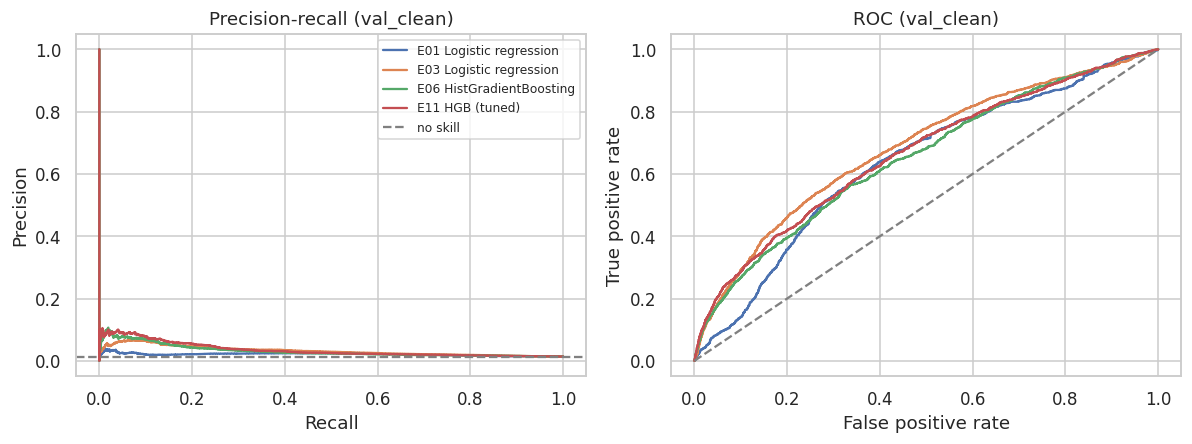

In [76]:
compare = ["E01", "E03", "E06", best_id]
compare = list(dict.fromkeys(compare))
yc = y_val[mask_clean]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for k in compare:
    sc = SCORES[k][mask_clean]
    p, r, _ = precision_recall_curve(yc, sc)
    fpr, tpr, _ = roc_curve(yc, sc)
    label = f"{k} {RESULTS[k]['model']}"
    axes[0].plot(r, p, label=label)
    axes[1].plot(fpr, tpr, label=label)
axes[0].axhline(yc.mean(), color="gray", ls="--", label="no skill")
axes[1].plot([0, 1], [0, 1], color="gray", ls="--")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision-recall (val_clean)")
axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (val_clean)")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

### 12.2 Confusion matrix at a 2% alert budget
Instead of the default 0.5 probability threshold (meaningless at this prevalence), the matrix flags the riskiest 2% of clean-validation flights. Reading it: top-left are correctly ignored flights, bottom-right are caught cancellations, top-right are false alarms, bottom-left are missed cancellations.

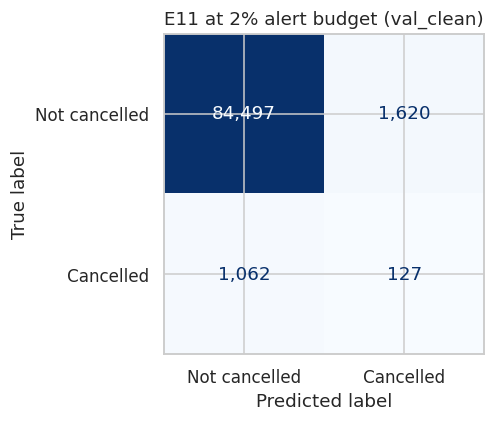

Flagged 1,747 flights; caught 127 of 1,189 cancellations (precision 0.073, recall 0.107)


In [77]:
sc = SCORES[best_id][mask_clean]
thr = np.quantile(sc, 1 - ALERT_FRAC)
pred = (sc >= thr).astype(int)
fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay.from_predictions(yc, pred, display_labels=["Not cancelled", "Cancelled"],
                                        values_format=",d", cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"{best_id} at 2% alert budget (val_clean)"); plt.tight_layout(); plt.show()
tp = int(((pred == 1) & (yc == 1)).sum())
print(f"Flagged {pred.sum():,} flights; caught {tp:,} of {int(yc.sum()):,} cancellations "
      f"(precision {tp / pred.sum():.3f}, recall {tp / yc.sum():.3f})")

**Interpretation.** *How many false alarms does the model pay for each caught cancellation? Is that acceptable for a passenger alert (cheap to ignore) versus an airport staffing decision (costly)? What does the missed-cancellation cell say about events that schedule-time features cannot see?*

### 12.3 Learning curves: diagnosing bias and variance
Two views. **Boosting rounds:** training versus validation PR-AUC as trees are added. A widening gap means the model is memorising training data (high variance); both curves flat and low means high bias. **Training-set size:** whether more data would help (curves still converging) or whether the model is limited by its features (curves flat and close together). The training curve here uses the out-of-fold target encodings the model was actually trained on, so it is not inflated by encoding leakage.

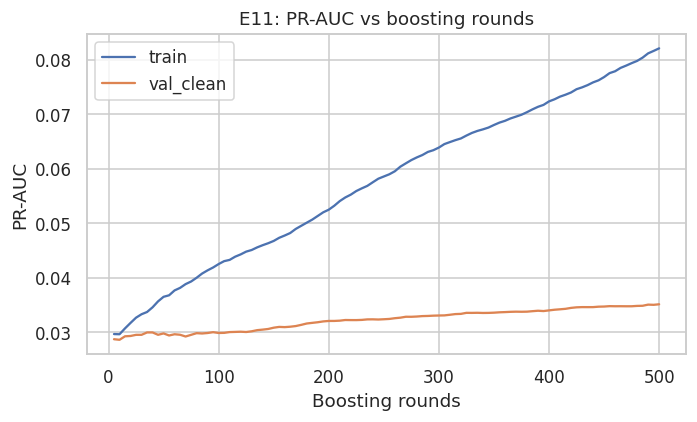

In [78]:
final_model = best_pipe.named_steps["model"]
if isinstance(final_model, HistGradientBoostingClassifier):
    prep = best_pipe.named_steps["prep"]
    sub = np.sort(np.random.default_rng(SEED).choice(len(X_train), size=min(150_000, len(X_train)), replace=False))
    tr_idx = np.arange(len(X_train)) if best_id != "E12" else us_idx
    Xt_all = clone(prep).fit_transform(X_train.iloc[tr_idx], y_train[tr_idx])   # out-of-fold encodings
    pos_in_sub = np.sort(np.random.default_rng(SEED).choice(len(tr_idx), size=min(150_000, len(tr_idx)), replace=False))
    Xt, yt = Xt_all[pos_in_sub], y_train[tr_idx][pos_in_sub]
    Xv, yv = prep.transform(X_val[mask_clean]), y_val[mask_clean]
    its, tr_ap, va_ap = [], [], []
    for i, (pt, pv) in enumerate(zip(final_model.staged_predict_proba(Xt), final_model.staged_predict_proba(Xv)), 1):
        if i % 5 == 0 or i == final_model.n_iter_:
            its.append(i); tr_ap.append(average_precision_score(yt, pt[:, 1])); va_ap.append(average_precision_score(yv, pv[:, 1]))
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.plot(its, tr_ap, label="train"); ax.plot(its, va_ap, label="val_clean")
    ax.set(xlabel="Boosting rounds", ylabel="PR-AUC", title=f"{best_id}: PR-AUC vs boosting rounds"); ax.legend()
    plt.tight_layout(); plt.show()
else:
    print(f"{best_id} is not a boosted model; skipping the per-round curve.")

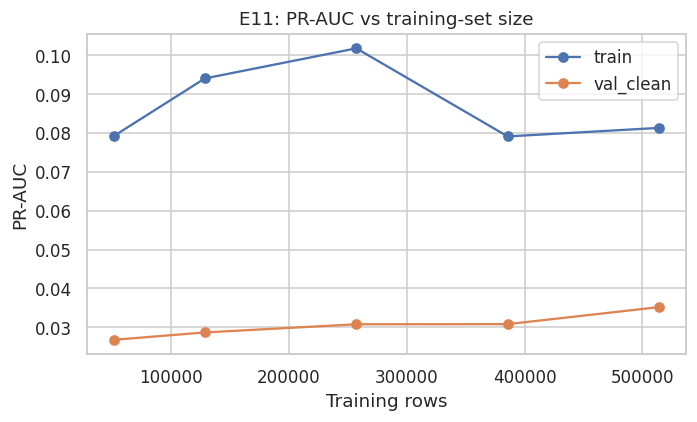

In [79]:
fractions = [0.1, 0.25, 0.5, 0.75, 1.0]
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(X_train))
sizes, tr_ap, va_ap = [], [], []
for f in fractions:
    idx = np.sort(perm[: int(f * len(perm))])
    p = clone(best_pipe).fit(X_train.iloc[idx], y_train[idx])
    ev = idx[:100_000]
    tr_ap.append(average_precision_score(y_train[ev], predict_scores(p, X_train.iloc[ev])))
    va_ap.append(average_precision_score(y_val[mask_clean], predict_scores(p, X_val[mask_clean])))
    sizes.append(len(idx))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(sizes, tr_ap, marker="o", label="train"); ax.plot(sizes, va_ap, marker="o", label="val_clean")
ax.set(xlabel="Training rows", ylabel="PR-AUC", title=f"{best_id}: PR-AUC vs training-set size"); ax.legend()
plt.tight_layout(); plt.show()

**Interpretation.** *Use the curves to diagnose the model. Is there a large, growing gap between training and validation PR-AUC (variance), or are both low (bias)? Does validation PR-AUC still rise with more data, or has it flattened? Relate what you see to the regularisation you chose (leaf size, L2, early stopping) and to the fact that most validation positives come from event days the features cannot see.*

### 12.4 Which features matter?
Permutation importance shuffles one input column at a time on clean-validation data and measures how much PR-AUC falls. It is computed on the raw input columns, so target-encoded and one-hot columns are measured as whole features. A large drop means the model relies on that feature.

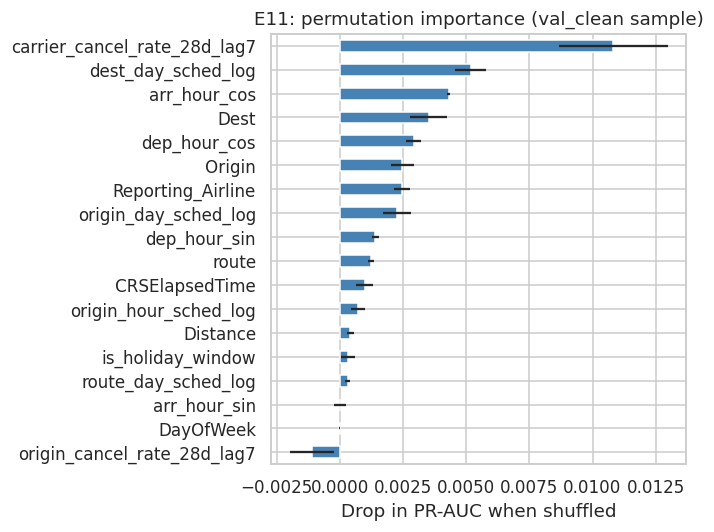

In [80]:
spec = FEATURE_SETS[best_fset]
used = spec["num"] + spec["ohe"] + spec["te"]
idx_v = np.random.default_rng(SEED).choice(mask_clean.sum(), size=min(60_000, mask_clean.sum()), replace=False)
Xv_sub = X_val[mask_clean].iloc[idx_v][used]
yv_sub = y_val[mask_clean][idx_v]
pi = permutation_importance(best_pipe, Xv_sub, yv_sub, scoring="average_precision", n_repeats=3,
                            random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=used).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 5))
imp.plot.barh(ax=ax, color="steelblue", xerr=pd.Series(pi.importances_std, index=used)[imp.index])
ax.set(xlabel="Drop in PR-AUC when shuffled", title=f"{best_id}: permutation importance (val_clean sample)")
plt.tight_layout(); plt.show()

**Interpretation.** *Which features carry the model? Do the trailing cancellation rates dominate, as the decile plots in Part 1 suggested? Which engineered features contribute almost nothing, and does that agree with the E02 vs E03 and E05 vs E06 comparisons?*

## 13. Saved artifacts
Download these from `/kaggle/working` (the Output tab) and upload them to the Google Drive folder: the best model (`best_ml_model.joblib`), the experiment log (`experiments.csv`) and, if created, the zipped offline W&B runs.

In [81]:
wb_dir = os.path.join(OUT_DIR, "wandb")
if os.path.isdir(wb_dir):
    shutil.make_archive(os.path.join(OUT_DIR, "wandb_offline_runs"), "zip", wb_dir)
for f in sorted(os.listdir(OUT_DIR)):
    p = os.path.join(OUT_DIR, f)
    if os.path.isfile(p):
        print(f"{f:35s} {os.path.getsize(p) / 1e6:8.1f} MB")

best_ml_model.joblib                     2.0 MB
experiments.csv                          0.0 MB
wandb_offline_runs.zip                   0.4 MB


## Part 2 summary
*Write four or five sentences in your own words: which model and feature set won, how much feature engineering and tuning each added, what the imbalance experiments showed, and what the learning curves say about bias and variance. These notes feed the Results and Discussion sections.*

**Next (Part 3):** the deep learning models (Keras with a `tf.data` pipeline and the same time-aware protocol), the final ML vs DL comparison on the untouched test set with confidence intervals, and error analysis by carrier, airport size and event days.